In [4]:
#1
#импорт файла
# Импортируем библиотеку os для работы с путями и размерами файлов.
import os

# Импортируем модуль files для ручной загрузки файла из Windows.
from google.colab import files

# Указываем ожидаемое имя исходного файла.
имя_файла = "исходные_данные.txt"

# В Colab файлы обычно находятся в папке /content.
путь_к_файлу = os.path.join("/content", имя_файла)

# Если файла нет, предлагаем загрузить его с компьютера.
if not os.path.isfile(путь_к_файлу):
    print("Выберите исходный файл на компьютере.")
    загруженные = files.upload()

    # Проверяем, что среди загруженных файлов есть нужный.
    if имя_файла not in загруженные:
        raise FileNotFoundError(
            "Не найден файл с именем исходные_данные.txt"
        )

# Получаем размер загруженного файла в байтах.
размер = os.path.getsize(путь_к_файлу)

# Размер полного исходного файла из предыдущего этапа.
ожидаемый_размер = 132960755

print("Файл:", путь_к_файлу)
print("Размер:", размер, "байт")

# Не разрешаем продолжать работу с неполным файлом.
if размер != ожидаемый_размер:
    raise ValueError(
        "Размер файла не совпадает с исходным. "
        "Проверьте загрузку."
    )

print("Проверка размера пройдена.")

Выберите исходный файл на компьютере.


Saving исходные_данные.txt to исходные_данные.txt
Файл: /content/исходные_данные.txt
Размер: 132960755 байт
Проверка размера пройдена.


In [5]:
#2
#повторяем шаг из этапа 2 и создаем рабочую таблицу
# pandas — библиотека для работы с таблицами.
import pandas as pd

# NumPy понадобится для числовых вычислений.
import numpy as np

# Читаем таблицу без преобразования исходных значений.
# sep=";" указывает разделитель столбцов.
# dtype=str сохраняет значения в виде текста.
# keep_default_na=False не превращает пустые строки в NaN.
исходная_таблица = pd.read_csv(
    путь_к_файлу,
    sep=";",
    encoding="utf-8",
    dtype=str,
    keep_default_na=False
)

# Соединяем дату и время через один пробел.
дата_и_время = (
    исходная_таблица["Date"]
    + " "
    + исходная_таблица["Time"]
)

# Преобразуем текст в тип datetime.
# %d — день, %m — месяц, %Y — год из четырёх цифр.
# %H — часы, %M — минуты, %S — секунды.
# errors="coerce": неправильные даты становятся NaT.
время = pd.to_datetime(
    дата_и_время,
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Создаём отдельную рабочую таблицу.
# Исходная таблица остаётся неизменённой.
рабочая_таблица = pd.DataFrame({
    "datetime": время.copy()
})

# Переводим основную переменную в числовой формат.
# Знак ? и пустые значения превратятся в NaN.
рабочая_таблица["Global_active_power"] = pd.to_numeric(
    исходная_таблица["Global_active_power"],
    errors="coerce"
)

# Считаем даты, которые отсутсуют (невозможно распознать).
ошибки_дат = int(время.isna().sum())

# ищем повторяющиеся временные метки.
# keep="first" отмечает только повторные экземпляры.
повторы = int(время.duplicated(keep="first").sum())

# Вычисляем разницу между соседними датами
# в первоначальном порядке строк.
разница_времени = время.diff()

# Отрицательная разница означает движение времени назад.
обратные_переходы = int(
    (разница_времени < pd.Timedelta(0)).sum()
)

# Проверяем ожидаемую минутную сетку.
# Начало и конец определяем по корректным датам.
временные_метки = pd.DatetimeIndex(время.dropna())

ожидаемые_метки = pd.date_range(
    start=временные_метки.min(),
    end=временные_метки.max(),
    freq="min"
)

# unique() удаляет повторы только из набора меток
# для проверки; строки исходной таблицы не удаляются.
уникальные_метки = временные_метки.unique()

# difference() находит ожидаемые минуты,
# которые отсутствуют среди имеющихся меток.
отсутствующие_метки = ожидаемые_метки.difference(
    уникальные_метки
)

# Считаем наблюдения с отсутствующей мощностью.
пропуски_мощности = int(
    рабочая_таблица["Global_active_power"].isna().sum()
)

# Проверяем, что число строк рабочей таблицы не изменилось.
assert len(рабочая_таблица) == len(исходная_таблица) #assert останавливает выполнение кода при невыполнении обязательного условия

print("Количество строк:", len(рабочая_таблица))
print("Ошибки дат:", ошибки_дат)
print("Повторные временные метки:", повторы)
print("Переходы времени назад:", обратные_переходы)
print("Отсутствующие минуты:", len(отсутствующие_метки))
print("Отсутствующая мощность:", пропуски_мощности)
print("Начало:", временные_метки.min())
print("Конец:", временные_метки.max())

Количество строк: 2075259
Ошибки дат: 0
Повторные временные метки: 0
Переходы времени назад: 0
Отсутствующие минуты: 0
Отсутствующая мощность: 25979
Начало: 2006-12-16 17:24:00
Конец: 2010-11-26 21:02:00


In [6]:
#3
#таблица
# Названия семи столбцов с электрическими измерениями.
измеряемые_переменные = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Для каждого измерения создаём:
# 1) числовой столбец;
# 2) признак корректности измерения (True или False).
#
# Исходную таблицу не изменяем.
for имя in измеряемые_переменные:

    # Преобразуем исходное значение в число.
    # Знак "?" и пустые значения станут NaN.
    числа = pd.to_numeric(
        исходная_таблица[имя],
        errors="coerce"
    )

    # Добавляем числовую переменную в рабочую таблицу.
    рабочая_таблица[имя] = числа

    # Проверяем, что значение является конечным числом.
    # Это исключает NaN, +inf и -inf.
    корректно = числа.notna() & np.isfinite(числа)

    # Активная мощность, ток и показания подсчётчиков
    # не должны быть отрицательными.
    if имя not in ["Voltage", "Global_reactive_power"]:
        корректно = корректно & (числа >= 0)

    # Напряжение в работающей измерительной системе
    # должно быть положительным.
    if имя == "Voltage":
        корректно = корректно & (числа > 0)

    # Для реактивной мощности пока не исключаем
    # отрицательные конечные значения автоматически:
    # их физический смысл требует отдельной проверки.

    # Сохраняем результаты проверки.
    рабочая_таблица["корректно_" + имя] = корректно

# Сортируем только рабочую таблицу по времени.
# kind="stable" сохраняет исходный порядок строк
# с одинаковыми временными метками.
рабочая_таблица = рабочая_таблица.sort_values(
    "datetime",
    kind="stable"
).reset_index(drop=True)

# Независимая проверка: число строк не изменилось.
assert len(рабочая_таблица) == len(исходная_таблица)

print("Строк после сортировки:", len(рабочая_таблица))

# Выводим число отсутствующих или некорректных
# измерений отдельно по каждой переменной.
for имя in измеряемые_переменные:
    число_проблем = (
        ~рабочая_таблица["корректно_" + имя]
    ).sum()

    print(имя, ":", int(число_проблем))


Строк после сортировки: 2075259
Global_active_power : 25979
Global_reactive_power : 25979
Voltage : 25979
Global_intensity : 25979
Sub_metering_1 : 25979
Sub_metering_2 : 25979
Sub_metering_3 : 25979


In [7]:
#4
#расчет полноты

from IPython.display import display

# Получаем начало и конец исследуемого периода.
начало = рабочая_таблица["datetime"].min()
конец = рабочая_таблица["datetime"].max()

# Создаём ожидаемую сетку из всех минут.
сетка = pd.date_range(
    start=начало,
    end=конец,
    freq="min"
)

# Список столбцов с признаками корректности.
признаки = [
    "корректно_" + имя
    for имя in измеряемые_переменные
]

# Группируем данные по временной метке.
# Если одна минута встретится дважды, учитываем её один раз.
# Метод max() для True/False означает:
# минута считается корректной, если есть хотя бы
# одно корректное измерение данной переменной.
по_минутам = рабочая_таблица.groupby(
    "datetime"
)[признаки].max()

# Отдельно фиксируем присутствие временной метки.
метка_есть = pd.Series(
    True,
    index=по_минутам.index
).reindex(
    сетка,
    fill_value=False
)

# Добавляем в проверочную таблицу все ожидаемые минуты.
# Отсутствующим минутам присваиваем False.
# Это не восстановление измерений, а учёт отсутствия данных.
по_минутам = по_минутам.reindex(
    сетка,
    fill_value=False
)

# Получаем список месяцев от начала до конца наблюдений.
месяцы = pd.period_range(
    start=начало.to_period("M"),
    end=конец.to_period("M"),
    freq="M"
)

# Здесь будем собирать строки итоговых таблиц.
результаты = []
результаты_по_переменным = []
числа_по_переменным = []

# Обрабатываем каждый месяц отдельно.
for месяц in месяцы:

    # Первый момент календарного месяца.
    начало_месяца = месяц.start_time

    # Последняя минута календарного месяца.
    конец_месяца = (
        (месяц + 1).start_time
        - pd.Timedelta(minutes=1)
    )

    # Границы фактического периода записи.
    # Особенно важно для декабря 2006 и ноября 2010.
    от = max(начало_месяца, начало)
    до = min(конец_месяца, конец)

    # Все ожидаемые минуты внутри периода записи.
    окно = по_минутам.loc[от:до]

    # Сколько минут в полном календарном месяце?
    ожидалось_календарно = месяц.days_in_month * 1440

    # Сколько минут ожидается внутри периода записи?
    ожидалось_в_периоде = len(окно)

    # Сколько разных временных меток действительно есть?
    представлено = int(метка_есть.loc[от:до].sum())

    # Основная анализируемая переменная.
    активная = окно["корректно_Global_active_power"]

    # Сколько минут содержат корректную активную мощность?
    корректных = int(активная.sum())

    # Сколько ожидаемых минут осталось без пригодного
    # измерения активной мощности?
    проблемных = ожидалось_в_периоде - корректных

    # Полнота внутри фактического периода наблюдения.
    полнота = 100 * корректных / ожидалось_в_периоде

    # Полнота относительно всего календарного месяца.
    полнота_календарная = (
        100 * корректных / ожидалось_календарно
    )

    # Считаем дни с хотя бы одной минутой без
    # корректной активной мощности.
    # Краевые неполные календарные дни оцениваем
    # только в пределах периода фактической записи.
    дни = активная.groupby(активная.index.normalize())

    неполных_дней = int(
        (дни.sum() < дни.size()).sum()
    )

    # Ищем последовательные минуты без измерений.
    отсутствует = ~активная

    # Новый номер группы возникает при смене
    # True на False или False на True.
    группы = отсутствует.ne(
        отсутствует.shift()
    ).cumsum()

    # Максимальная продолжительность одного
    # непрерывного пропуска в данном месяце.
    максимальный_пропуск = int(
        отсутствует.groupby(группы).sum().max()
    )

    # Добавляем одну строку в таблицу по месяцам.
    результаты.append({
        "Месяц": str(месяц),
        "Ожидалось за полный месяц": ожидалось_календарно,
        "Ожидалось в период записи": ожидалось_в_периоде,
        "Уникальных временных меток": представлено,
        "Корректных измерений": корректных,
        "Без корректного измерения": проблемных,
        "Полнота периода, %": round(полнота, 3),
        "Полнота месяца, %": round(полнота_календарная, 3),
        "Неполных дней": неполных_дней,
        "Максимальный пропуск, мин": максимальный_пропуск,
        "Есть пропуск от 60 мин": максимальный_пропуск >= 60
    })

    # Отдельно рассчитываем полноту всех 7 переменных.
    строка_процентов = {"Месяц": str(месяц)}
    строка_количеств = {"Месяц": str(месяц)}

    for имя in измеряемые_переменные:

        n = int(окно["корректно_" + имя].sum())

        строка_процентов[имя] = round(
            100 * n / ожидалось_в_периоде,
            3
        )

        строка_количеств[имя] = n

    результаты_по_переменным.append(строка_процентов)
    числа_по_переменным.append(строка_количеств)

# Создаём итоговые таблицы.
таблица_полноты = pd.DataFrame(результаты)

полнота_переменных = pd.DataFrame(
    результаты_по_переменным
)

количества_переменных = pd.DataFrame(
    числа_по_переменным
)

# Контрольные проверки.
assert таблица_полноты["Ожидалось в период записи"].sum() == len(сетка)

assert таблица_полноты["Уникальных временных меток"].sum() == (
    рабочая_таблица["datetime"].nunique()
)

# Показываем все месяцы.
pd.set_option("display.max_rows", 60)

print("ТАБЛИЦА ПОЛНОТЫ ПО МЕСЯЦАМ")
display(таблица_полноты)

print("\nПОЛНОТА СЕМИ ПЕРЕМЕННЫХ, %")
display(полнота_переменных)

# Проверяем различия по исходным количествам, а не по округлённым процентам.
различия = (
    количества_переменных[измеряемые_переменные]
    .nunique(axis=1) > 1
)

print(
    "\nМесяцев с разной полнотой переменных:",
    int(различия.sum())
)

print(
    "Всего минут без корректной активной мощности:",
    int(таблица_полноты["Без корректного измерения"].sum())
)

print("Количество месяцев:", len(таблица_полноты))


ТАБЛИЦА ПОЛНОТЫ ПО МЕСЯЦАМ


,Месяц,Ожидалось за полный месяц,Ожидалось в период записи,Уникальных временных меток,Корректных измерений,Без корректного измерения,"Полнота периода, %","Полнота месяца, %",Неполных дней,"Максимальный пропуск, мин",Есть пропуск от 60 мин
0,2006-12,44640,21996,21996,21992,4,99.982,49.265,2,2,False
1,2007-01,44640,44640,44640,44638,2,99.996,99.996,2,1,False
2,2007-02,40320,40320,40320,40318,2,99.995,99.995,1,2,False
3,2007-03,44640,44640,44640,44639,1,99.998,99.998,1,1,False
4,2007-04,43200,43200,43200,39477,3723,91.382,91.382,3,3723,True
5,2007-05,44640,44640,44640,44640,0,100.000,100.000,0,0,False
6,2007-06,43200,43200,43200,43157,43,99.900,99.900,5,33,False
7,2007-07,44640,44640,44640,44509,131,99.707,99.707,2,83,True
8,2007-08,44640,44640,44640,44618,22,99.951,99.951,2,21,False
9,2007-09,43200,43200,43200,43198,2,99.995,99.995,1,2,False



ПОЛНОТА СЕМИ ПЕРЕМЕННЫХ, %


,Месяц,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12,99.982,99.982,99.982,99.982,99.982,99.982,99.982
1,2007-01,99.996,99.996,99.996,99.996,99.996,99.996,99.996
2,2007-02,99.995,99.995,99.995,99.995,99.995,99.995,99.995
3,2007-03,99.998,99.998,99.998,99.998,99.998,99.998,99.998
4,2007-04,91.382,91.382,91.382,91.382,91.382,91.382,91.382
5,2007-05,100.000,100.000,100.000,100.000,100.000,100.000,100.000
6,2007-06,99.900,99.900,99.900,99.900,99.900,99.900,99.900
7,2007-07,99.707,99.707,99.707,99.707,99.707,99.707,99.707
8,2007-08,99.951,99.951,99.951,99.951,99.951,99.951,99.951
9,2007-09,99.995,99.995,99.995,99.995,99.995,99.995,99.995



Месяцев с разной полнотой переменных: 0
Всего минут без корректной активной мощности: 25979
Количество месяцев: 48


In [9]:
#5
#проверка длинных пропусков

# Находим минуты без корректного измерения мощности.
нет_измерения = ~рабочая_таблица[
    "корректно_Global_active_power"
]

# Каждая смена состояния (есть измерение / нет измерения)
# начинает новую последовательность.
номера_серий = нет_измерения.ne(
    нет_измерения.shift()
).cumsum()

# Выбираем только строки с пропусками.
# В исходной таблице ничего не удаляем.
пропущенные_строки = рабочая_таблица.loc[
    нет_измерения, ["datetime"]
]

# Для каждого непрерывного участка пропусков
# находим начало, конец и количество минут.
серии_пропусков = (
    пропущенные_строки
    .groupby(номера_серий[нет_измерения])["datetime"]
    .agg(["min", "max", "size"])
    .rename(columns={
        "min": "Начало",
        "max": "Конец",
        "size": "Продолжительность, мин"
    })
    .reset_index(drop=True)
)

# Проверяем, проходит ли участок через границу месяца.
серии_пропусков["Пересекает месяцы"] = (
    серии_пропусков["Начало"].dt.to_period("M")
    != серии_пропусков["Конец"].dt.to_period("M")
)

# Независимая проверка всех пропущенных минут.
assert (
    серии_пропусков["Продолжительность, мин"].sum()
    == 25979
)

print("Всего минут без измерений: 25979")
print(
    "Число серий через границу месяцев:",
    int(серии_пропусков["Пересекает месяцы"].sum())
)

print("\nДесять самых длинных пропусков:")
display(
    серии_пропусков.sort_values(
        "Продолжительность, мин",
        ascending=False
    ).head(10)
)


Всего минут без измерений: 25979
Число серий через границу месяцев: 0

Десять самых длинных пропусков:


,Начало,Конец,"Продолжительность, мин",Пересекает месяцы
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,False
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,False
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,False
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,False
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,False
62,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,False
51,2009-08-13 05:00:00,2009-08-13 19:50:00,891,False
15,2007-07-15 16:49:00,2007-07-15 18:11:00,83,False
38,2008-12-10 10:48:00,2008-12-10 11:57:00,70,False
16,2007-07-15 18:21:00,2007-07-15 19:07:00,47,False


In [10]:

# pathlib используется для работы с именами файлов.
from pathlib import Path

# Импортируем инструмент скачивания файлов из Colab.
from google.colab import files

# Определяем имена трёх итоговых таблиц.
файл_месяцев = Path("03_полнота_по_месяцам.csv")
файл_переменных = Path("03_полнота_переменных.csv")
файл_пропусков = Path("03_серии_пропусков.csv")

# Сохраняем таблицы в CSV.
# index=False: не записываем служебные номера строк.
# sep=";" — разделитель, удобный для открытия в Excel.
# encoding="utf-8-sig" — кодировка для русских названий.
таблица_полноты.to_csv(
    файл_месяцев,
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

полнота_переменных.to_csv(
    файл_переменных,
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

серии_пропусков.to_csv(
    файл_пропусков,
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

# Проверяем, что файлы созданы и не пустые.
for файл in [
    файл_месяцев,
    файл_переменных,
    файл_пропусков
]:
    assert файл.exists() and файл.stat().st_size > 0

    print("Сохранено:", файл.name)

# Скачиваем результаты из Colab в Windows.
for файл in [
    файл_месяцев,
    файл_переменных,
    файл_пропусков
]:
    files.download(str(файл))


Сохранено: 03_полнота_по_месяцам.csv
Сохранено: 03_полнота_переменных.csv
Сохранено: 03_серии_пропусков.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
#7
# Перечисляем утверждённые месяцы.
# Сентябрь 2008 используется сразу в двух направлениях (сохраняем его только один раз).

выбранные_месяцы = [
    "2008-01",  # Зима
    "2008-04",  # Весна
    "2008-07",  # Лето
    "2008-09",  # Осень и эталон без пропусков
    "2009-08",  # Реальные пропуски
    "2010-08"   # Длительные реальные пропуски
]

# Определяем месяц каждой записи рабочей таблицы.
# dt.to_period("M") оставляет только год и месяц.
месяц_записи = рабочая_таблица[
    "datetime"
].dt.to_period("M").astype(str)

# Создаём словарь отдельных рабочих таблиц.
# Ключ словаря — месяц, значение — его таблица.
рабочие_месяцы = {}

for месяц in выбранные_месяцы:

    # Выбираем строки нужного месяца.
    условие = месяц_записи == месяц

    # .copy() создаёт самостоятельную копию.
    # Изменения в ней не затронут общую рабочую таблицу.
    рабочие_месяцы[месяц] = (
        рабочая_таблица.loc[условие].copy()
    )

    # Получаем ожидаемое количество минут
    # из уже рассчитанной таблицы полноты.
    ожидается = int(
        таблица_полноты.loc[
            таблица_полноты["Месяц"] == месяц,
            "Ожидалось в период записи"
        ].iloc[0]
    )

    # Проверяем, что ни одна строка месяца не потеряна.
    assert len(рабочие_месяцы[месяц]) == ожидается

    print(
        месяц,
        "— строк:",
        len(рабочие_месяцы[месяц])
    )

print("\nРабочие копии успешно созданы.")


2008-01 — строк: 44640
2008-04 — строк: 43200
2008-07 — строк: 44640
2008-09 — строк: 43200
2009-08 — строк: 44640
2010-08 — строк: 44640

Рабочие копии успешно созданы.


In [12]:
#8
#преобразования величин
# Импортируем библиотеку NumPy для последующих проверок.
import numpy as np

# Импортируем pandas для работы с таблицами.
import pandas as pd

# Импортируем функцию удобного отображения таблиц.
from IPython.display import display

# Перечисляем месяцы, утверждённые для исследования.
# Используем четыре сезона 2008 года и два неполных
# по измерениям августа для экспериментов с пропусками.
выбранные_месяцы = [
    "2008-01",
    "2008-04",
    "2008-07",
    "2008-09",
    "2009-08",
    "2010-08"
]

# Переводим дату каждой записи в обозначение года и месяца.
месяц_строки = (
    рабочая_таблица["datetime"]
    .dt.to_period("M")
    .astype(str)
)

# Выбираем строки, относящиеся к нужным месяцам.
# Метод isin() проверяет принадлежность к списку месяцев.
маска = месяц_строки.isin(выбранные_месяцы)

# Список столбцов, которые сохраняем без изменений.
исходные_столбцы = [
    "datetime",
    "Global_active_power",
    "корректно_Global_active_power",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "корректно_Sub_metering_1",
    "корректно_Sub_metering_2",
    "корректно_Sub_metering_3"
]

# Создаём самостоятельную копию выбранных измерений.
# deep=True означает копирование данных.
# reset_index() создаёт новую нумерацию строк.
физические_данные = (
    рабочая_таблица.loc[маска, исходные_столбцы]
    .copy(deep=True)
    .reset_index(drop=True)
)

# Сохраняем контрольную копию выбранных столбцов.
# Позднее убедимся, что их значения не изменились.
контрольная_копия = физические_данные.copy(deep=True)

# ПРЕОБРАЗОВАНИЕ № 1.
# Средняя активная мощность записана в кВт.
# Продолжительность одной минуты равна 1/60 часа.
# Поэтому P / 60 даёт энергию за минуту в кВт·ч.
#
# where() оставляет только корректные измерения.
# Для неизвестной мощности энергия остаётся NaN.
физические_данные["Energy_active_kWh"] = (
    физические_данные["Global_active_power"]
    .where(
        физические_данные["корректно_Global_active_power"]
    )
    / 60
)

# ПРЕОБРАЗОВАНИЕ № 2.
# Все три подсчётчика уже содержат энергию в Вт·ч.
# Для перевода в кВт·ч делим на 1000.
for номер in [1, 2, 3]:

    # Формируем имя исходного столбца подсчётчика.
    старый_столбец = f"Sub_metering_{номер}"

    # Формируем имя нового столбца энергии.
    новый_столбец = f"Energy_sub_{номер}_kWh"

    # Получаем признак корректности измерения.
    признак = f"корректно_Sub_metering_{номер}"

    # Преобразуем Вт·ч в кВт·ч.
    # Некорректные значения не заменяем нулями.
    физические_данные[новый_столбец] = (
        физические_данные[старый_столбец]
        .where(физические_данные[признак])
        / 1000
    )

# Отображаем только несколько строк.
# Все остальные значения остаются в рабочей таблице.
print("Количество строк:", len(физические_данные))

display(
    физические_данные[
        [
            "datetime",
            "Global_active_power",
            "Energy_active_kWh",
            "Sub_metering_3",
            "Energy_sub_3_kWh"
        ]
    ].head(10)
)


Количество строк: 264960


,datetime,Global_active_power,Energy_active_kWh,Sub_metering_3,Energy_sub_3_kWh
0,2008-01-01 00:00:00,1.620,0.027000,18.0,0.018
1,2008-01-01 00:01:00,1.626,0.027100,18.0,0.018
2,2008-01-01 00:02:00,1.622,0.027033,18.0,0.018
3,2008-01-01 00:03:00,1.612,0.026867,18.0,0.018
4,2008-01-01 00:04:00,1.612,0.026867,18.0,0.018
5,2008-01-01 00:05:00,1.546,0.025767,17.0,0.017
6,2008-01-01 00:06:00,1.544,0.025733,18.0,0.018
7,2008-01-01 00:07:00,1.550,0.025833,18.0,0.018
8,2008-01-01 00:08:00,1.548,0.025800,18.0,0.018
9,2008-01-01 00:09:00,1.548,0.025800,18.0,0.018


In [14]:
#9
#независимая проверка величин
# ПРОВЕРКА № 1.
# Постоянная мощность 2 кВт в течение одного часа
# должна соответствовать энергии 2 кВт·ч.
энергия_за_час = 2 * 1

assert np.isclose(энергия_за_час, 2)

print("Проверка 1: энергия за час — верно")

# ПРОВЕРКА № 2.
# При мощности 2 кВт за одну минуту
# энергия должна составить 2/60 кВт·ч.
энергия_за_минуту = 2 / 60

assert np.isclose(энергия_за_минуту, 1 / 30)

print("Проверка 2: энергия за минуту — верно")

# ПРОВЕРКА № 3.
# Сравним два независимых способа вычисления энергии.
#
# Способ А: мощность 4.216 кВт и время 1/60 ч.
энергия_кВтч = 4.216 / 60

# Способ Б: переводим мощность в Вт,
# умножаем на 60 секунд и получаем джоули.
энергия_Дж = 4.216 * 1000 * 60

# Переводим джоули в кВт·ч.
энергия_из_Дж = энергия_Дж / 3600000

# Результаты должны совпасть.
assert np.isclose(энергия_кВтч, энергия_из_Дж)

print("Проверка 3: преобразование через джоули — верно")

# ПРОВЕРКА № 4.
# Проверяем перевод 17 Вт·ч в кВт·ч.
энергия_подсчетчика = 17 / 1000

assert np.isclose(энергия_подсчетчика, 0.017)

print("Проверка 4: перевод Вт·ч в кВт·ч — верно")

# ПРОВЕРКА № 5.
# Проверяем, что преобразование можно обратить:
# умножение минутной энергии на 60 возвращает мощность.
#
# Выбираем только строки с корректной мощностью.
есть_мощность = физические_данные[
    "корректно_Global_active_power"
]

# np.allclose() сравнивает два набора чисел
# с учётом небольших ошибок округления.
assert np.allclose(
    физические_данные.loc[
        есть_мощность, "Energy_active_kWh"
    ] * 60,
    физические_данные.loc[
        есть_мощность, "Global_active_power"
    ]
)

print("Проверка 5: обратное преобразование — верно")

# ПРОВЕРКА № 6.
# Сравниваем исходные столбцы с контрольной копией.
# Новые вычисления не должны изменять прежние значения.
pd.testing.assert_frame_equal(
    физические_данные[исходные_столбцы],
    контрольная_копия
)

print("Проверка 6: исходные значения не изменены")

# ПРОВЕРКА № 7.
# Сравниваем число пропусков до и после преобразования.
пропусков_до = int(
    физические_данные["Global_active_power"].isna().sum()
)

пропусков_после = int(
    физические_данные["Energy_active_kWh"].isna().sum()
)

assert пропусков_до == пропусков_после

# Для шести выбранных месяцев ожидаем 8120 пропусков:
# январь 2008: 1; апрель: 0; июль: 2;
# сентябрь: 0; август 2009: 891; август 2010: 7226.
assert пропусков_после == 8120

print("Проверка 7: пропуски сохранены — верно")

print("\nВсе проверки успешно пройдены.")


Проверка 1: энергия за час — верно
Проверка 2: энергия за минуту — верно
Проверка 3: преобразование через джоули — верно
Проверка 4: перевод Вт·ч в кВт·ч — верно
Проверка 5: обратное преобразование — верно
Проверка 6: исходные значения не изменены
Проверка 7: пропуски сохранены — верно

Все проверки успешно пройдены.


In [15]:
#
#контроль вычислений и таблица физ величин

# Импортируем pandas и NumPy.
import pandas as pd
import numpy as np

# Функция display показывает таблицы в Colab.
from IPython.display import display

# Проверяем число строк за шесть выбранных месяцев.
# Четыре месяца имеют 31 день, два месяца — 30 дней.
ожидаемое_число_строк = (4 * 31 + 2 * 30) * 24 * 60

assert len(физические_данные) == ожидаемое_число_строк

# Проверяем отсутствие повторяющихся временных меток.
assert физические_данные["datetime"].is_unique

# Проверяем, что отсутствующие значения не были заполнены.
число_пропусков = int(
    физические_данные["Energy_active_kWh"].isna().sum()
)

assert число_пропусков == 8120

# Получаем строки с корректной активной мощностью.
корректные_строки = физические_данные[
    "корректно_Global_active_power"
]

# Независимо рассчитываем энергию через джоули.
#
# Киловатты переводим в ватты: умножаем на 1000.
# Для энергии за минуту умножаем на 60 секунд.
# Получаем джоули.
энергия_в_джоулях = (
    физические_данные.loc[
        корректные_строки, "Global_active_power"
    ] * 1000 * 60
)

# Переводим джоули в кВт·ч.
# В одном кВт·ч содержится 3 600 000 Дж.
энергия_через_джоули = (
    энергия_в_джоулях / 3600000
)

# Сравниваем с ранее рассчитанным столбцом.
assert np.allclose(
    энергия_через_джоули,
    физические_данные.loc[
        корректные_строки, "Energy_active_kWh"
    ]
)

# Проверяем перевод каждого подсчётчика.
for номер in [1, 2, 3]:

    # Имя исходного столбца в Вт·ч.
    источник = f"Sub_metering_{номер}"

    # Имя нового столбца в кВт·ч.
    результат = f"Energy_sub_{номер}_kWh"

    # Выбираем корректные значения подсчётчика.
    подходит = физические_данные[
        f"корректно_Sub_metering_{номер}"
    ]

    # Обратный перевод кВт·ч в Вт·ч.
    восстановленные_значения = (
        физические_данные.loc[подходит, результат] * 1000
    )

    # Сравниваем с исходными показаниями.
    assert np.allclose(
        восстановленные_значения,
        физические_данные.loc[подходит, источник]
    )

    # Проверяем, что пропуски остались пропусками.
    assert физические_данные.loc[
        ~подходит, результат
    ].isna().all()

# Проверяем сохранность исходных столбцов
# относительно контрольной копии из первой ячейки.
pd.testing.assert_frame_equal(
    физические_данные[исходные_столбцы],
    контрольная_копия
)

print("Все проверки преобразования пройдены.")
print("Строк:", len(физические_данные))
print("Отсутствующих значений энергии:", число_пропусков)

# Показываем три реальные строки для ручной проверки.
print("\nПримеры реальных измерений:")
display(
    физические_данные.loc[
        корректные_строки,
        [
            "datetime",
            "Global_active_power",
            "Energy_active_kWh",
            "Sub_metering_3",
            "Energy_sub_3_kWh"
        ]
    ].head(3)
)

# Создаём документацию с описанием исходных величин.
# Это отдельная таблица, а не изменение исходного файла.
описание_величин = pd.DataFrame(
    [
        ["Date", "Дата", "дд/мм/гггг",
         "Объединение с Time", "datetime"],

        ["Time", "Время", "чч:мм:сс",
         "Объединение с Date", "datetime"],

        ["Global_active_power", "Средняя активная мощность",
         "кВт", "Деление на 60", "кВт·ч за минуту"],

        ["Global_reactive_power", "Реактивная мощность",
         "В UCI указано кВт; физически квар",
         "Не выполняется", "Исходная величина"],

        ["Voltage", "Среднее напряжение",
         "В", "Не выполняется", "В"],

        ["Global_intensity", "Средняя сила тока",
         "А", "Не выполняется", "А"],

        ["Sub_metering_1", "Энергия подсчётчика 1",
         "Вт·ч", "Деление на 1000", "кВт·ч"],

        ["Sub_metering_2", "Энергия подсчётчика 2",
         "Вт·ч", "Деление на 1000", "кВт·ч"],

        ["Sub_metering_3", "Энергия подсчётчика 3",
         "Вт·ч", "Деление на 1000", "кВт·ч"]
    ],
    columns=[
        "Исходный столбец",
        "Физический смысл",
        "Исходная единица",
        "Преобразование",
        "Единица результата"
    ]
)

print("\nОписание физических величин:")
display(описание_величин)


Все проверки преобразования пройдены.
Строк: 264960
Отсутствующих значений энергии: 8120

Примеры реальных измерений:


,datetime,Global_active_power,Energy_active_kWh,Sub_metering_3,Energy_sub_3_kWh
0,2008-01-01 00:00:00,1.620,0.027000,18.0,0.018
1,2008-01-01 00:01:00,1.626,0.027100,18.0,0.018
2,2008-01-01 00:02:00,1.622,0.027033,18.0,0.018



Описание физических величин:


,Исходный столбец,Физический смысл,Исходная единица,Преобразование,Единица результата
0,Date,Дата,дд/мм/гггг,Объединение с Time,datetime
1,Time,Время,чч:мм:сс,Объединение с Date,datetime
2,Global_active_power,Средняя активная мощность,кВт,Деление на 60,кВт·ч за минуту
3,Global_reactive_power,Реактивная мощность,В UCI указано кВт; физически квар,Не выполняется,Исходная величина
4,Voltage,Среднее напряжение,В,Не выполняется,В
5,Global_intensity,Средняя сила тока,А,Не выполняется,А
6,Sub_metering_1,Энергия подсчётчика 1,Вт·ч,Деление на 1000,кВт·ч
7,Sub_metering_2,Энергия подсчётчика 2,Вт·ч,Деление на 1000,кВт·ч
8,Sub_metering_3,Энергия подсчётчика 3,Вт·ч,Деление на 1000,кВт·ч


In [16]:

# Path помогает работать с файлами и папками.
from pathlib import Path

# zipfile создаёт ZIP-архивы.
import zipfile

# files.download позволяет скачивать файлы из Colab.
from google.colab import files

# Создаём отдельную папку для результатов.
# Исходные данные эта операция не затрагивает.
папка = Path("/content/результаты_этапа_4")
папка.mkdir(parents=True, exist_ok=True)

# Определяем пути новых файлов.
файл_энергии = папка / "04_минутная_энергия.csv"
файл_описания = папка / "04_описание_величин.csv"
файл_методики = папка / "04_методика_преобразования.txt"

# Сохраняем рабочие данные с новыми столбцами энергии.
# index=False исключает служебную нумерацию строк.
# sep=";" устанавливает разделитель CSV.
# UTF-8-SIG позволяет корректно читать русские заголовки
# в Windows и некоторых табличных программах.
физические_данные.to_csv(
    файл_энергии,
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

# Сохраняем таблицу физических величин.
описание_величин.to_csv(
    файл_описания,
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

# Создаём текстовое описание методики исследования.
методика = """
ЭТАП 4. ФИЗИЧЕСКИЕ ВЕЛИЧИНЫ И ПРЕОБРАЗОВАНИЕ ЕДИНИЦ

Основная величина:
Средняя за минуту активная мощность Global_active_power.

Исходная единица: кВт.
Единица энергии: кВт·ч.
Продолжительность измерительного интервала: 1 минута.

ФОРМУЛА ПРЕОБРАЗОВАНИЯ

E_мин (кВт·ч) = P_ср (кВт) / 60

Обоснование:
E = интеграл P(t) dt.
Если P_ср — средняя мощность за минуту,
то E_мин = P_ср * (1/60 часа).

ПОДСЧЁТЧИКИ

Исходные показания Sub_metering_1, 2 и 3
представляют энергию за минуту в Вт·ч.

E (кВт·ч) = E (Вт·ч) / 1000

РЕАКТИВНАЯ МОЩНОСТЬ

В описании UCI указана единица kilowatt.
В электротехнике единица реактивной мощности — квар.
Этот столбец не используется для расчёта активной энергии.

ПРИНЯТЫЕ ДОПУЩЕНИЯ И ОГРАНИЧЕНИЯ

1. Используется минутная средняя активная мощность.
2. Погрешности и округление исходных измерений сохраняются.
3. Предполагается соответствие каждого показания
   одному минутному интервалу.
4. Точная привязка временной метки к границе интервала
   не устанавливается по имеющейся документации.
5. Пропущенные измерения не заменяются нулями.
6. Интерполяция и сглаживание не выполняются.
7. При пропусках сумма известных минутных энергий
   не считается энергией полного периода.
8. Исходный файл не изменяется.

СТАНДАРТ ДАЛЬНЕЙШИХ ГРАФИКОВ

Мощность: кВт.
Энергия: кВт·ч.
Время суток: часы и минуты.
Нельзя обозначать энергию в кВт или мощность в кВт·ч.

Метод трапеций рассматривается теоретически.
Для минутных средних мощностей выбран расчёт
энергии через произведение средней мощности
на длительность минутного интервала.

Источник описания данных:
https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
""".strip()

# Сохраняем методику в обычный текстовый файл.
файл_методики.write_text(
    методика,
    encoding="utf-8-sig"
)

# Проверяем, что все три файла действительно созданы.
for путь in [файл_энергии, файл_описания, файл_методики]:
    assert путь.exists()
    assert путь.stat().st_size > 0

# Определяем путь ZIP-архива.
архив = папка / "04_результаты_преобразования.zip"

# Собираем файлы в один архив.
with zipfile.ZipFile(
    архив,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_файл:

    zip_файл.write(
        файл_энергии,
        arcname="04. Обработанные данные/04_минутная_энергия.csv"
    )

    zip_файл.write(
        файл_описания,
        arcname="07. Научная документация/04_описание_величин.csv"
    )

    zip_файл.write(
        файл_методики,
        arcname="07. Научная документация/04_методика_преобразования.txt"
    )

# Проверяем содержимое архива.
with zipfile.ZipFile(архив) as zip_файл:
    assert len(zip_файл.namelist()) == 3

print("Архив успешно создан.")
print("Содержит 3 файла.")
print("Размер архива:", архив.stat().st_size, "байт")

# Скачиваем архив на компьютер.
files.download(str(архив))


Архив успешно создан.
Содержит 3 файла.
Размер архива: 2261766 байт


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

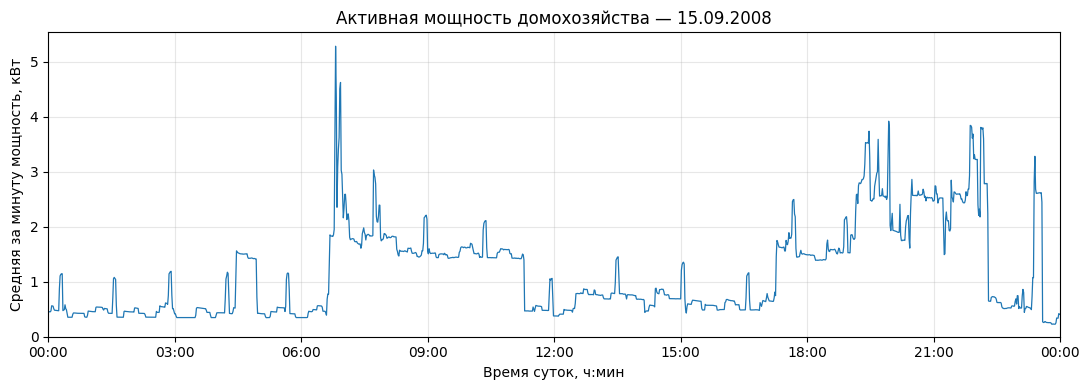

Количество минутных записей: 1440
Отсутствующих измерений: 0
Графики сохранены в: /content/04_Графики


In [17]:
#график за сутки
# Импортируем pandas для работы с датами и таблицами.
import pandas as pd

# Импортируем Matplotlib для построения графиков.
import matplotlib.pyplot as plt

# Модуль dates нужен для форматирования времени на оси X.
import matplotlib.dates as mdates

# Path используется для создания папки с рисунками.
from pathlib import Path

# Проверяем, что рабочая таблица существует в памяти.
assert "рабочая_таблица" in globals(), (
    "Сначала выполните ячейки создания рабочая_таблица"
)

# Проверяем наличие необходимых столбцов.
assert {"datetime", "Global_active_power"}.issubset(
    рабочая_таблица.columns
)

# Создаём папку для графиков в среде Colab.
# Исходные данные при этом не изменяются.
папка_графиков = Path("/content/04_Графики")
папка_графиков.mkdir(parents=True, exist_ok=True)

# Указываем начало рассматриваемых суток.
начало = pd.Timestamp("2008-09-15 00:00:00")

# Указываем начало следующих суток.
# Правая граница в нашем отборе не включается.
конец = pd.Timestamp("2008-09-16 00:00:00")

# Выбираем записи только внутри этих суток.
маска = (
    (рабочая_таблица["datetime"] >= начало)
    & (рабочая_таблица["datetime"] < конец)
)

# Создаём отдельную копию выбранных строк.
# Оставляем только время и активную мощность.
сутки = рабочая_таблица.loc[
    маска, ["datetime", "Global_active_power"]
].copy(deep=True)

# Упорядочиваем записи по времени.
сутки = сутки.sort_values("datetime")

# Проверяем количество минут в сутках.
assert len(сутки) == 1440

# Проверяем отсутствие повторяющихся меток времени.
assert сутки["datetime"].is_unique

# Считаем количество отсутствующих измерений мощности.
пропуски = int(сутки["Global_active_power"].isna().sum())

# Для полностью наблюдаемого сентября ожидаем ноль.
assert пропуски == 0

# Создаём рисунок и область для графика.
# figsize задаёт размеры рисунка в дюймах.
рисунок, ось = plt.subplots(figsize=(11, 4))

# Строим кривую исходных минутных значений мощности.
# linewidth задаёт толщину линии.
ось.plot(
    сутки["datetime"],
    сутки["Global_active_power"],
    linewidth=0.9,
    color="tab:blue"
)

# Добавляем содержательный заголовок.
ось.set_title(
    "Активная мощность домохозяйства — 15.09.2008"
)

# Подписываем горизонтальную ось.
ось.set_xlabel("Время суток, ч:мин")

# Подписываем вертикальную ось с единицей мощности.
ось.set_ylabel("Средняя за минуту мощность, кВт")

# Устанавливаем ноль в качестве нижней границы мощности.
ось.set_ylim(bottom=0)

# Ограничиваем горизонтальную ось выбранными сутками.
ось.set_xlim(начало, конец)

# Размещаем основные отметки времени каждые три часа.
ось.xaxis.set_major_locator(mdates.HourLocator(interval=3))

# Выводим время в формате часы:минуты.
ось.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

# Добавляем неброскую сетку для чтения значений.
ось.grid(True, alpha=0.3)

# Автоматически подбираем отступы элементов рисунка.
рисунок.tight_layout()

# Сохраняем PNG с разрешением 300 точек на дюйм.
рисунок.savefig(
    папка_графиков / "04_viz_01_day_2008-09-15.png",
    dpi=300
)

# Сохраняем масштабируемую векторную версию SVG.
рисунок.savefig(
    папка_графиков / "04_viz_01_day_2008-09-15.svg"
)

# Выводим рисунок прямо под ячейкой Colab.
plt.show()

# Закрываем объект рисунка после сохранения.
plt.close(рисунок)

# Показываем информацию для проверки.
print("Количество минутных записей:", len(сутки))
print("Отсутствующих измерений:", пропуски)
print("Графики сохранены в:", папка_графиков)


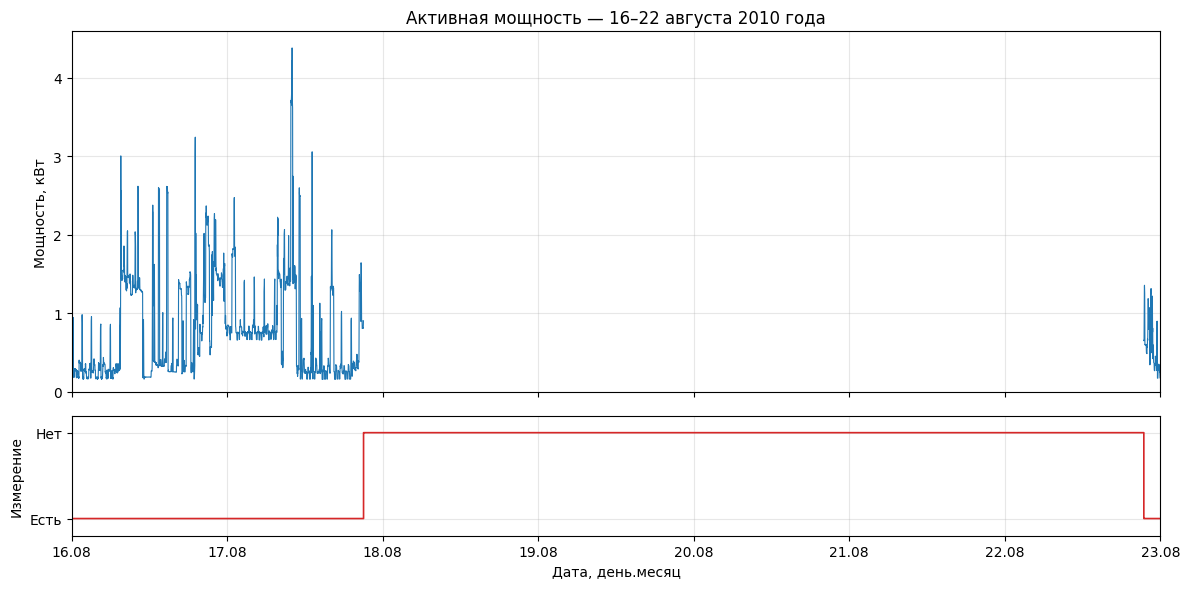

Всего минут в неделе: 10080
Отсутствующих измерений: 7226
Корректных измерений: 2854


In [18]:
# график неделя с длительным пропуском

# Указываем начало исследуемой недели.
начало_недели = pd.Timestamp("2010-08-16 00:00:00")

# Конец интервала не включаем.
конец_недели = pd.Timestamp("2010-08-23 00:00:00")

# Создаём условие выбора записей за неделю.
маска_недели = (
    (рабочая_таблица["datetime"] >= начало_недели)
    & (рабочая_таблица["datetime"] < конец_недели)
)

# Создаём независимую копию двух исходных столбцов.
неделя = рабочая_таблица.loc[
    маска_недели, ["datetime", "Global_active_power"]
].copy(deep=True)

# Сортируем записи по времени.
неделя = неделя.sort_values("datetime")

# Проверяем количество минут за семь суток.
assert len(неделя) == 10080

# Проверяем отсутствие повторяющихся меток времени.
assert неделя["datetime"].is_unique

# Создаём маску отсутствующих измерений.
# True означает, что значение мощности неизвестно.
нет_измерения = неделя["Global_active_power"].isna()

# Подсчитываем число отсутствующих измерений.
число_пропусков = int(нет_измерения.sum())

# Сравниваем с результатом предыдущего этапа.
assert число_пропусков == 7226

# Создаём два графика на одном рисунке.
# sharex=True означает общую ось времени.
рисунок, (ось_мощности, ось_пропусков) = plt.subplots(
    2,
    1,
    figsize=(12, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Строим график активной мощности.
# Отсутствующие значения NaN разрывают линию.
ось_мощности.plot(
    неделя["datetime"],
    неделя["Global_active_power"],
    linewidth=0.8,
    color="tab:blue"
)

# Добавляем заголовок первого графика.
ось_мощности.set_title(
    "Активная мощность — 16–22 августа 2010 года"
)

# Указываем физическую величину и единицу.
ось_мощности.set_ylabel("Мощность, кВт")

# Устанавливаем нижнюю границу мощности.
ось_мощности.set_ylim(bottom=0)

# Включаем сетку.
ось_мощности.grid(True, alpha=0.3)

# Преобразуем логические значения в числа.
# 0 означает, что измерение есть.
# 1 означает, что измерение отсутствует.
индикатор_пропуска = нет_измерения.astype(int)

# Строим ступенчатую кривую наличия измерений.
ось_пропусков.step(
    неделя["datetime"],
    индикатор_пропуска,
    where="post",
    linewidth=1.2,
    color="tab:red"
)

# Задаём понятные обозначения уровней.
ось_пропусков.set_yticks([0, 1])
ось_пропусков.set_yticklabels(["Есть", "Нет"])

# Подписываем вертикальную ось.
ось_пропусков.set_ylabel("Измерение")

# Устанавливаем границы индикатора.
ось_пропусков.set_ylim(-0.2, 1.2)

# Подписываем горизонтальную ось.
ось_пропусков.set_xlabel("Дата, день.месяц")

# Размещаем отметки каждый день.
ось_пропусков.xaxis.set_major_locator(
    mdates.DayLocator(interval=1)
)

# Задаём формат подписи календарной даты.
ось_пропусков.xaxis.set_major_formatter(
    mdates.DateFormatter("%d.%m")
)

# Ограничиваем горизонтальную ось выбранной неделей.
ось_пропусков.set_xlim(начало_недели, конец_недели)

# Добавляем сетку на нижнем графике.
ось_пропусков.grid(True, alpha=0.3)

# Подбираем отступы.
рисунок.tight_layout()

# Сохраняем рисунок в PNG.
рисунок.savefig(
    папка_графиков / "04_viz_02_missing_week_2010-08.png",
    dpi=300
)

# Сохраняем векторный SVG.
рисунок.savefig(
    папка_графиков / "04_viz_02_missing_week_2010-08.svg"
)

# Показываем графики.
plt.show()

# Освобождаем память после сохранения.
plt.close(рисунок)

# Выводим контрольные показатели.
print("Всего минут в неделе:", len(неделя))
print("Отсутствующих измерений:", число_пропусков)
print("Корректных измерений:", len(неделя) - число_пропусков)


Сентябрь 2008 — строк: 43200 — пропусков: 0
Август 2010 — строк: 44640 — пропусков: 7226


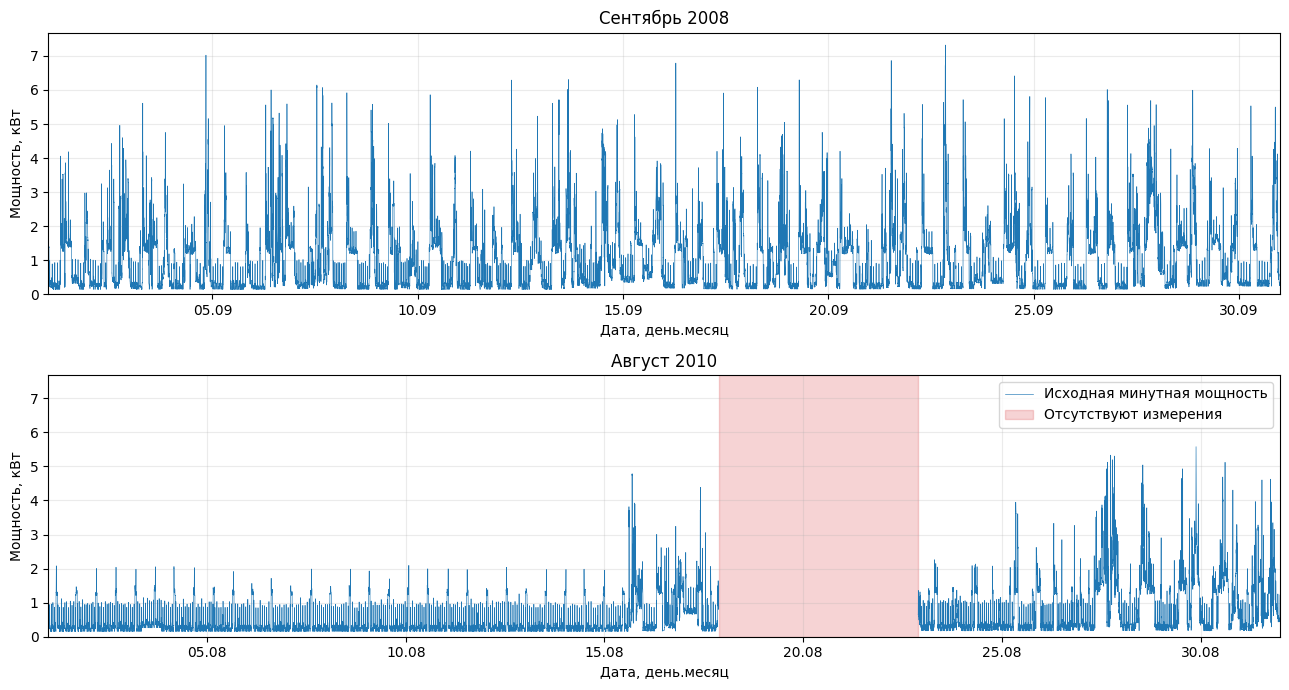

In [19]:
#2 графика: Сентябрь 2008, Август 2010
# Импортируем библиотеку pandas для работы с таблицами.
import pandas as pd

# Импортируем Matplotlib для построения рисунков.
import matplotlib.pyplot as plt

# Импортируем инструменты форматирования дат.
import matplotlib.dates as mdates

# Проверяем наличие таблицы из предыдущих этапов.
assert "рабочая_таблица" in globals()

# Проверяем наличие папки, созданной ранее.
assert "папка_графиков" in globals()

# Указываем два месяца для визуального сравнения.
месяцы_графика = [
    ("2008-09", "Сентябрь 2008"),
    ("2010-08", "Август 2010")
]

# Создаём словарь для двух отдельных таблиц.
данные_месяцев = {}

# Последовательно обрабатываем каждый месяц.
for месяц, название in месяцы_графика:

    # Находим начало календарного месяца.
    начало = pd.Timestamp(месяц + "-01")

    # Находим начало следующего календарного месяца.
    конец = начало + pd.offsets.MonthBegin(1)

    # Выбираем только строки внутри нужного месяца.
    маска = (
        (рабочая_таблица["datetime"] >= начало)
        & (рабочая_таблица["datetime"] < конец)
    )

    # Копируем время и мощность, не меняя исходную таблицу.
    таблица = рабочая_таблица.loc[
        маска, ["datetime", "Global_active_power"]
    ].copy(deep=True)

    # Упорядочиваем данные по времени.
    таблица = таблица.sort_values("datetime")

    # Рассчитываем ожидаемое число минут месяца.
    ожидается = начало.days_in_month * 24 * 60

    # Проверяем полноту временной сетки.
    assert len(таблица) == ожидается

    # Проверяем уникальность временных меток.
    assert таблица["datetime"].is_unique

    # Сохраняем таблицу для построения графика.
    данные_месяцев[месяц] = таблица

    # Считаем отсутствующие значения мощности.
    пропуски = int(
        таблица["Global_active_power"].isna().sum()
    )

    # Показываем информацию для проверки.
    print(название, "— строк:", len(таблица),
          "— пропусков:", пропуски)

# Проверяем ожидаемые количества пропусков.
assert данные_месяцев["2008-09"][
    "Global_active_power"
].isna().sum() == 0

assert данные_месяцев["2010-08"][
    "Global_active_power"
].isna().sum() == 7226

# Находим максимальную мощность среди обоих месяцев.
# Нужна одинаковая вертикальная шкала рисунков.
общий_максимум = max(
    таблица["Global_active_power"].max()
    for таблица in данные_месяцев.values()
)

# Создаём две области графика друг под другом.
# sharey=True устанавливает общую шкалу мощности.
рисунок, оси = plt.subplots(
    2, 1, figsize=(13, 7), sharey=True
)

# Строим один график для каждого месяца.
for ось, (месяц, название) in zip(оси, месяцы_графика):

    # Получаем подготовленные минутные измерения.
    таблица = данные_месяцев[месяц]

    # Строим исходную мощность по времени.
    # Значения NaN автоматически разрывают линию.
    ось.plot(
        таблица["datetime"],
        таблица["Global_active_power"],
        color="tab:blue",
        linewidth=0.45,
        label="Исходная минутная мощность"
    )

    # Устанавливаем одинаковый масштаб мощности.
    ось.set_ylim(0, общий_максимум * 1.05)

    # Подписываем физическую величину и единицу.
    ось.set_ylabel("Мощность, кВт")

    # Добавляем заголовок с названием месяца.
    ось.set_title(название)

    # Устанавливаем календарные границы месяца.
    начало = pd.Timestamp(месяц + "-01")
    конец = начало + pd.offsets.MonthBegin(1)
    ось.set_xlim(начало, конец)

    # Размещаем подписи дат с шагом пять суток.
    ось.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    # Устанавливаем формат календарных дат.
    ось.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m")
    )

    # Добавляем неброскую сетку.
    ось.grid(True, alpha=0.25)

    # Подписываем горизонтальную ось.
    ось.set_xlabel("Дата, день.месяц")

# Получаем отсутствующие измерения августа 2010.
август = данные_месяцев["2010-08"]

# Выбираем временные метки с отсутствующей мощностью.
времена_пропуска = август.loc[
    август["Global_active_power"].isna(), "datetime"
]

# Выделяем красным большую область отсутствия данных.
# Для августа 2010 все 7226 пропусков образуют один блок.
оси[1].axvspan(
    времена_пропуска.min(),
    времена_пропуска.max() + pd.Timedelta(minutes=1),
    color="tab:red",
    alpha=0.2,
    label="Отсутствуют измерения"
)

# Показываем легенду на графике с пропуском.
оси[1].legend(loc="upper right")

# Подбираем отступы между графиками.
рисунок.tight_layout()

# Сохраняем PNG для научного отчёта.
рисунок.savefig(
    папка_графиков / "04_viz_03_months.png",
    dpi=300
)

# Сохраняем также векторный рисунок.
рисунок.savefig(
    папка_графиков / "04_viz_03_months.svg"
)

# Показываем готовый рисунок.
plt.show()


Зима — январь | точек профиля: 1440 | минимум наблюдений: 30 | максимум: 31
Весна — апрель | точек профиля: 1440 | минимум наблюдений: 30 | максимум: 30
Лето — июль | точек профиля: 1440 | минимум наблюдений: 30 | максимум: 31
Осень — сентябрь | точек профиля: 1440 | минимум наблюдений: 30 | максимум: 30


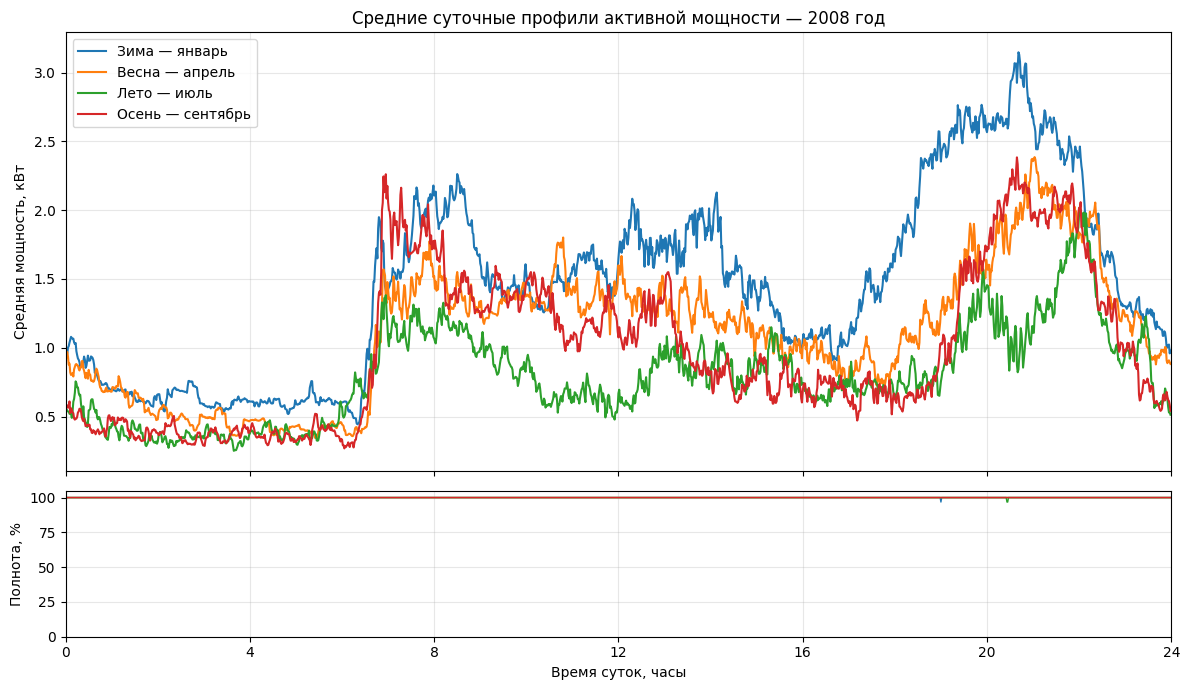


Первые пять строк таблицы профилей:


,Minute_of_day,Hour,Time_HHMM,P_2008-01_kW,N_2008-01,Coverage_2008-01_pct,P_2008-04_kW,N_2008-04,Coverage_2008-04_pct,P_2008-07_kW,N_2008-07,Coverage_2008-07_pct,P_2008-09_kW,N_2008-09,Coverage_2008-09_pct
0,0,0.000000,00:00,0.955935,31,100.0,0.930000,30,100.0,0.527355,31,100.0,0.587467,30,100.0
1,1,0.016667,00:01,0.945935,31,100.0,0.928933,30,100.0,0.552968,31,100.0,0.584533,30,100.0
2,2,0.033333,00:02,0.948903,31,100.0,0.969067,30,100.0,0.538645,31,100.0,0.580067,30,100.0
3,3,0.050000,00:03,1.000516,31,100.0,0.938333,30,100.0,0.537290,31,100.0,0.563867,30,100.0
4,4,0.066667,00:04,1.011613,31,100.0,0.877800,30,100.0,0.536581,31,100.0,0.576133,30,100.0



Таблица профилей сохранена для LabPlot.


In [20]:
# графики сезонных профилей (примером сезона служит только 1 месяц) и полнота их измерений
# ожидание: в выбранных месяцах могут различаться часы пиков, уровень ночной мощности и форма дневных колебаний

# Импортируем библиотеки для расчётов и графиков.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Указываем сезоны и соответствующие месяцы.
сезоны = {
    "2008-01": "Зима — январь",
    "2008-04": "Весна — апрель",
    "2008-07": "Лето — июль",
    "2008-09": "Осень — сентябрь"
}

# Создаём 1440 номеров минут внутри суток.
# Номер 0 означает 00:00, а 1439 — 23:59.
минуты = np.arange(1440)

# Создаём таблицу, в которую запишем все профили.
таблица_профилей = pd.DataFrame({
    "Minute_of_day": минуты
})

# Добавляем время в часах для построения оси X.
таблица_профилей["Hour"] = минуты / 60

# Добавляем удобное представление времени для CSV.
таблица_профилей["Time_HHMM"] = [
    f"{м // 60:02d}:{м % 60:02d}" for м in минуты
]

# Последовательно обрабатываем четыре месяца.
for месяц, название in сезоны.items():

    # Определяем первую минуту месяца.
    начало = pd.Timestamp(месяц + "-01")

    # Определяем начало следующего месяца.
    конец = начало + pd.offsets.MonthBegin(1)

    # Выбираем записи только рассматриваемого месяца.
    маска = (
        (рабочая_таблица["datetime"] >= начало)
        & (рабочая_таблица["datetime"] < конец)
    )

    # Создаём независимую копию нужных столбцов.
    данные = рабочая_таблица.loc[
        маска, ["datetime", "Global_active_power"]
    ].copy(deep=True)

    # Проверяем количество календарных минут.
    число_дней = начало.days_in_month
    assert len(данные) == число_дней * 1440

    # Проверяем уникальность временных меток.
    assert данные["datetime"].is_unique

    # Каждому времени сопоставляем номер минуты суток.
    # Например, 08:30 соответствует 8*60+30 = 510.
    данные["минута_суток"] = (
        данные["datetime"].dt.hour * 60
        + данные["datetime"].dt.minute
    )

    # Группируем измерения по минуте суток.
    # mean() находит среднюю мощность в кВт.
    # count() считает только известные значения мощности.
    группировка = (
        данные.groupby("минута_суток")[
            "Global_active_power"
        ]
        .agg(["mean", "count"])
        .reindex(range(1440))
    )

    # Сохраняем среднюю мощность каждой минуты.
    # Например, P_2008-01_kW — профиль января.
    таблица_профилей[f"P_{месяц}_kW"] = (
        группировка["mean"].to_numpy()
    )

    # Сохраняем число доступных наблюдений.
    таблица_профилей[f"N_{месяц}"] = (
        группировка["count"].to_numpy()
    )

    # Вычисляем долю доступных дней для каждой минуты.
    # Результат выражен в процентах.
    таблица_профилей[f"Coverage_{месяц}_pct"] = (
        группировка["count"].to_numpy()
        / число_дней * 100
    )

    # Проверяем, что число доступных измерений
    # не превышает число календарных дней.
    assert (группировка["count"] <= число_дней).all()

    # Проверяем, что сумма количеств по минутам
    # равна общему числу известных значений месяца.
    assert int(группировка["count"].sum()) == (
        len(данные)
        - int(данные["Global_active_power"].isna().sum())
    )

    # Показываем контрольную информацию.
    print(
        название,
        "| точек профиля:", len(группировка),
        "| минимум наблюдений:",
        int(группировка["count"].min()),
        "| максимум:",
        int(группировка["count"].max())
    )

# Проверяем количество строк итоговой таблицы.
assert len(таблица_профилей) == 1440

# Создаём рисунок с двумя областями.
# Верхняя — средняя мощность.
# Нижняя — полнота наблюдений.
рисунок, (ось_мощности, ось_полноты) = plt.subplots(
    2, 1, figsize=(12, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Строим кривые всех четырёх сезонов.
for месяц, название in сезоны.items():

    # Верхний график — средняя мощность в кВт.
    ось_мощности.plot(
        таблица_профилей["Hour"],
        таблица_профилей[f"P_{месяц}_kW"],
        linewidth=1.5,
        label=название
    )

    # Нижний график — доля известных измерений.
    ось_полноты.plot(
        таблица_профилей["Hour"],
        таблица_профилей[f"Coverage_{месяц}_pct"],
        linewidth=1,
        label=название
    )

# Подписываем главный график.
ось_мощности.set_title(
    "Средние суточные профили активной мощности — 2008 год"
)

# Указываем единицы вертикальной оси.
ось_мощности.set_ylabel("Средняя мощность, кВт")

# Добавляем легенду для четырёх месяцев.
ось_мощности.legend()

# Добавляем сетку.
ось_мощности.grid(True, alpha=0.3)

# Подписываем нижний график полноты.
ось_полноты.set_ylabel("Полнота, %")

# Показываем диапазон полноты от 0 до 100%.
ось_полноты.set_ylim(0, 105)

# Добавляем сетку на нижний график.
ось_полноты.grid(True, alpha=0.3)

# Подписываем общую временную ось.
ось_полноты.set_xlabel("Время суток, часы")

# Указываем диапазон от 0 до 24 часов.
ось_полноты.set_xlim(0, 24)

# Размещаем подписи каждые четыре часа.
ось_полноты.set_xticks(np.arange(0, 25, 4))

# Подбираем отступы между графиками.
рисунок.tight_layout()

# Сохраняем рисунок в PNG.
рисунок.savefig(
    папка_графиков / "04_viz_04_seasonal_profiles.png",
    dpi=300
)

# Сохраняем масштабируемый SVG.
рисунок.savefig(
    папка_графиков / "04_viz_04_seasonal_profiles.svg"
)

# Сохраняем также PDF для научного отчёта.
рисунок.savefig(
    папка_графиков / "04_viz_04_seasonal_profiles.pdf"
)

# Показываем рисунок в Colab.
plt.show()

# Закрываем рисунок после сохранения.
plt.close(рисунок)

# Показываем первые пять строк расчётной таблицы.
print("\nПервые пять строк таблицы профилей:")
display(таблица_профилей.head())

# Создаём папку для экспорта таблиц.
папка_экспорта = папка_графиков.parent / "04_Экспорт"
папка_экспорта.mkdir(parents=True, exist_ok=True)

# Экспортируем данные профилей для LabPlot.
# Разделитель — точка с запятой.
# Десятичный разделитель — точка.
таблица_профилей.to_csv(
    папка_экспорта / "04_viz_daily_profiles_2008.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
    float_format="%.8f"
)

# Проверяем создание CSV.
assert (
    папка_экспорта / "04_viz_daily_profiles_2008.csv"
).exists()

print("\nТаблица профилей сохранена для LabPlot.")


In [22]:
#создание файла для labplot

# Импортируем pandas для работы с таблицами.
import pandas as pd

# Импортируем NumPy для проверки числовых значений.
import numpy as np

# Импортируем Path для работы с путями к файлам.
from pathlib import Path

# Импортируем средство скачивания файлов из Colab.
from google.colab import files

# Проверяем, что таблица профилей уже рассчитана.
assert "таблица_профилей" in globals()

# Перечисляем столбцы для графиков в LabPlot.
нужные_столбцы = [
    "Hour",
    "P_2008-01_kW",
    "P_2008-04_kW",
    "P_2008-07_kW",
    "P_2008-09_kW",
    "Coverage_2008-01_pct",
    "Coverage_2008-04_pct",
    "Coverage_2008-07_pct",
    "Coverage_2008-09_pct"
]

# Проверяем, что все нужные столбцы существуют.
assert set(нужные_столбцы).issubset(
    таблица_профилей.columns
)

# Создаём отдельную таблицу только с нужными данными.
# Исходную таблицу профилей не изменяем.
данные_labplot = таблица_профилей[
    нужные_столбцы
].copy(deep=True)

# Проверяем количество минут внутри суток.
assert len(данные_labplot) == 1440

# Проверяем начало и конец временной оси.
assert np.isclose(данные_labplot["Hour"].iloc[0], 0)
assert np.isclose(
    данные_labplot["Hour"].iloc[-1], 1439 / 60
)

# Проверяем, что средние мощности рассчитаны
# для всех 1440 минут в каждом выбранном месяце.
assert данные_labplot[
    нужные_столбцы[1:5]
].notna().all().all()

# Проверяем допустимые значения полноты.
# Полнота должна находиться между 0 и 100%.

# Выбираем четыре столбца с процентами полноты.
полнота_labplot = данные_labplot[нужные_столбцы[5:9]]

# Проверяем, что все значения не меньше 0%.
проверка_нижней_границы = полнота_labplot >= 0

# Проверяем, что все значения не больше 100%.
проверка_верхней_границы = полнота_labplot <= 100

# Объединяем проверки и убеждаемся,
# что они выполнены для всех строк и столбцов.
assert (
    проверка_нижней_границы
    & проверка_верхней_границы
).all().all()

# Создаём папку для экспорта.
папка = Path("/content/04_Экспорт")
папка.mkdir(parents=True, exist_ok=True)

# Определяем имя нового CSV-файла.
путь_csv = папка / "04_viz_labplot_profiles_2008.csv"

# Сохраняем таблицу с разделителем «;».
# Десятичным разделителем остаётся точка.
данные_labplot.to_csv(
    путь_csv,
    sep=";",
    index=False,
    encoding="utf-8-sig",
    float_format="%.8f"
)

# Независимо считываем сохранённый файл.
контроль = pd.read_csv(
    путь_csv,
    sep=";",
    encoding="utf-8-sig"
)

# Проверяем число строк и порядок столбцов.
assert контроль.shape == (1440, 9)
assert контроль.columns.tolist() == нужные_столбцы

# Проверяем числовые данные после сохранения.
# Допуск связан с округлением до восьми знаков.
assert np.allclose(
    контроль.to_numpy(dtype=float),
    данные_labplot.to_numpy(dtype=float),
    rtol=0,
    atol=0.00000001
)

# Показываем результат.
print("CSV создан и проверен.")
print("Строк:", len(контроль))
print("Столбцов:", len(контроль.columns))
print("Путь:", путь_csv)

# Скачиваем подготовленный CSV на компьютер.
files.download(str(путь_csv))


CSV создан и проверен.
Строк: 1440
Столбцов: 9
Путь: /content/04_Экспорт/04_viz_labplot_profiles_2008.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>